In [1]:
# import libraries
from keras.utils import to_categorical
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from tensorflow import keras
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
import matplotlib.pyplot as plt
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler

def scores(X_train, y_train, y_pred_train, y_pred_test, method_used, scores_table=None):
    # Calculate the confusion matrix for train and test sets
    confusion_mat_train = confusion_matrix(y_train, y_pred_train)
    confusion_mat_test = confusion_matrix(y_test, y_pred_test)

    num_class_1_train = sum(y_train == 1)
    num_class_1_test = sum(y_test == 1)

    # Extract TP, TN, FP, FN from the confusion matrix for train set
    TP_train = confusion_mat_train[1, 1]
    TN_train = confusion_mat_train[0, 0]
    FP_train = confusion_mat_train[0, 1]
    FN_train = confusion_mat_train[1, 0]

    # Extract TP, TN, FP, FN from the confusion matrix for test set
    TP_test = confusion_mat_test[1, 1]
    TN_test = confusion_mat_test[0, 0]
    FP_test = confusion_mat_test[0, 1]
    FN_test = confusion_mat_test[1, 0]

    # Calculate Precision, Recall, and F1 score for train set
    precision_train = TP_train / (TP_train + FP_train)
    recall_train = TP_train / (TP_train + FN_train)
    f1_train = 2 * (precision_train * recall_train) / (precision_train + recall_train)

    # Calculate Precision, Recall, and F1 score for test set
    precision_test = TP_test / (TP_test + FP_test)
    recall_test = TP_test / (TP_test + FN_test)
    f1_test = 2 * (precision_test * recall_test) / (precision_test + recall_test)

    # Calculate Accuracy for train and test sets
    accuracy_train = accuracy_score(y_train, y_pred_train)
    accuracy_test = accuracy_score(y_test, y_pred_test)

    # Calculate the success rate in class 0 and class 1 for test sets
    success_rate_class0_test = TN_test / (TN_test + FP_test)
    success_rate_class0_test = f"{success_rate_class0_test*100:.2f}%"
    success_rate_class1_test = TP_test / (TP_test + FN_test)
    success_rate_class1_test = f"{success_rate_class1_test*100:.2f}%"

    # Create a dictionary of scores
    scores_dict_train = {
        'Method': method_used,
        'Sample': 'Train',
        'Number_of_training_samples': len(X_train),
        'Number_of_bankrupt_companies': num_class_1_train,
        'TP': TP_train,
        'TN': TN_train,
        'FP': FP_train,
        'FN': FN_train,
        'Precision': precision_train,
        'Recall': recall_train,
        'F1': f1_train,
        'Accuracy': accuracy_train,
        'Succ_rate_healthy_comp': '-',
        'Succ_rate_bankrupt_comp': '-'

    }

    scores_dict_test = {
        'Method': method_used,
        'Sample': 'Test',
        'Number_of_training_samples': len(X_test),
        'Number_of_bankrupt_companies': num_class_1_test,
        'TP': TP_test,
        'TN': TN_test,
        'FP': FP_test,
        'FN': FN_test,
        'Precision': precision_test,
        'Recall': recall_test,
        'F1': f1_test,
        'Accuracy': accuracy_test,
        'Succ_rate_healthy_comp':  success_rate_class0_test,
        'Succ_rate_bankrupt_comp': success_rate_class1_test

    }

    # Append the scores to the existing scores table or create a new one if None
    if scores_table is None:
        scores_table = pd.concat([pd.DataFrame(scores_dict_train, index=[0]),
                                  pd.DataFrame(scores_dict_test, index=[0])], ignore_index=True)
    else:
        scores_table = pd.concat([scores_table, pd.DataFrame(scores_dict_train, index=[0]),
                                  pd.DataFrame(scores_dict_test, index=[0])], ignore_index=True)

    return scores_table

    # Append the scores to the existing scores table or create a new one if None
    if scores_table is None:
        scores_table = pd.DataFrame(scores_dict, index=[0])
    else:
        scores_table = scores_table.append(scores_dict, ignore_index=True)

    return scores_table



In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
######################################################################################################################################################################################################
# read the data             edw prwta xwrizw test train meta kanw preprocess
######################################################################################################################################################################################################
fileName = '/content/drive/MyDrive/Colab Notebooks/deep Learning/Dataset2Use_PartA.xlsx'

try:
    sheetValues = pd.read_excel(fileName)
    print('.. successful parsing of file:', fileName)
    print("Column headings:")
    print(sheetValues.columns)
except FileNotFoundError:
    print(FileNotFoundError)

# create the input array with values
end_index = sheetValues.columns.get_loc('ΕΝΔΕΙΞΗ ΑΝΤΙΠΡΟΣΩΠΕΙΩΝ')

inputData = sheetValues.iloc[:, :end_index].values
outputData = sheetValues['ΕΝΔΕΙΞΗ ΑΣΥΝΕΠΕΙΑΣ (=2) (ν+1)']
outputData, levels = pd.factorize(outputData)

print('.. we have', inputData.shape[0], 'available paradigms.')
print('.. each paradigm has', inputData.shape[1], 'features')

print('... the distribution for the available class labels is:')

for classIdx in range(0, len(np.unique(outputData))):
    tmpCount = sum(outputData == classIdx)
    tmpPercentage = tmpCount / len(outputData)
    print('.. class', str(classIdx), 'has', str(tmpCount), 'instances', '(', '{:.2f}'.format(tmpPercentage), '%)')


.. successful parsing of file: /content/drive/MyDrive/Colab Notebooks/deep Learning/Dataset2Use_PartA.xlsx
Column headings:
Index(['365* ( Β.Υ / Κοστ.Πωλ )', 'Λειτ.Αποτ/Συν.Ενεργ. (ROA)',
       'ΧΡΗΜ.ΔΑΠΑΝΕΣ / ΠΩΛΗΣΕΙΣ',
       ' ΠΡΑΓΜΑΤΙΚΗ ΡΕΥΣΤΟΤΗΤΑ :  (ΚΕ-ΑΠΟΘΕΜΑΤΑ) / Β.Υ', '(ΑΠΑΙΤ.*365) / ΠΩΛ.',
       'Συν.Υποχρ/Συν.Ενεργ', 'Διάρκεια Παραμονής Αποθεμάτων',
       'Λογαριθμος Προσωπικού', 'ΕΝΔΕΙΞΗ ΕΞΑΓΩΓΩΝ', 'ΕΝΔΕΙΞΗ ΕΙΣΑΓΩΓΩΝ',
       'ΕΝΔΕΙΞΗ ΑΝΤΙΠΡΟΣΩΠΕΙΩΝ', 'ΕΝΔΕΙΞΗ ΑΣΥΝΕΠΕΙΑΣ (=2) (ν+1)', 'ΕΤΟΣ'],
      dtype='object')
.. we have 10716 available paradigms.
.. each paradigm has 10 features
... the distribution for the available class labels is:
.. class 0 has 10468 instances ( 0.98 %)
.. class 1 has 248 instances ( 0.02 %)


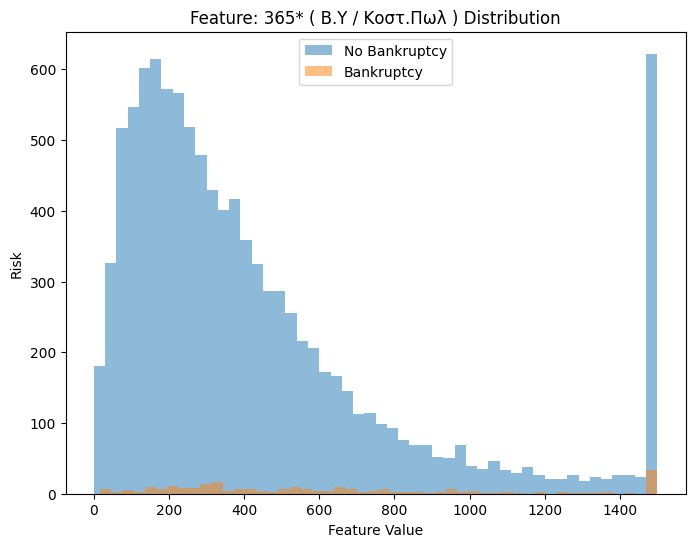

Υπάρχει ένα imbalanced σύνολο δεδομένων. Πρέπει αυτό να αντιμετωπιστεί κατάλληλα για την καλύτερη εκπαίδευση στα δεδομένα. 


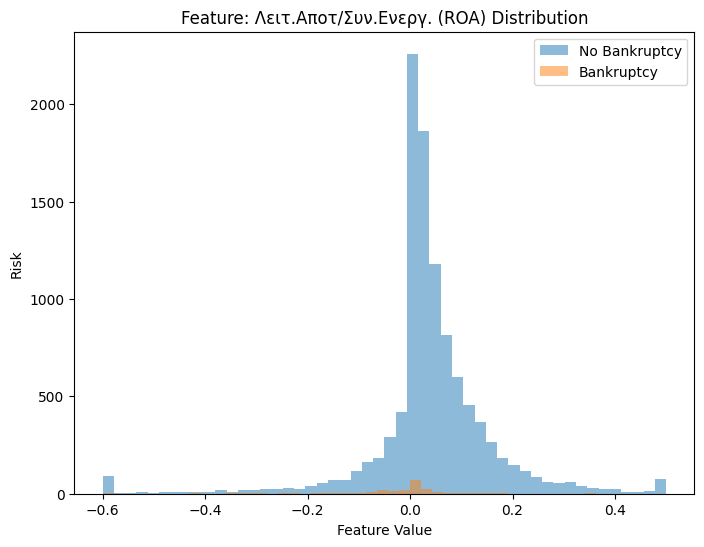

Υπάρχει ένα imbalanced σύνολο δεδομένων. Πρέπει αυτό να αντιμετωπιστεί κατάλληλα για την καλύτερη εκπαίδευση στα δεδομένα. 


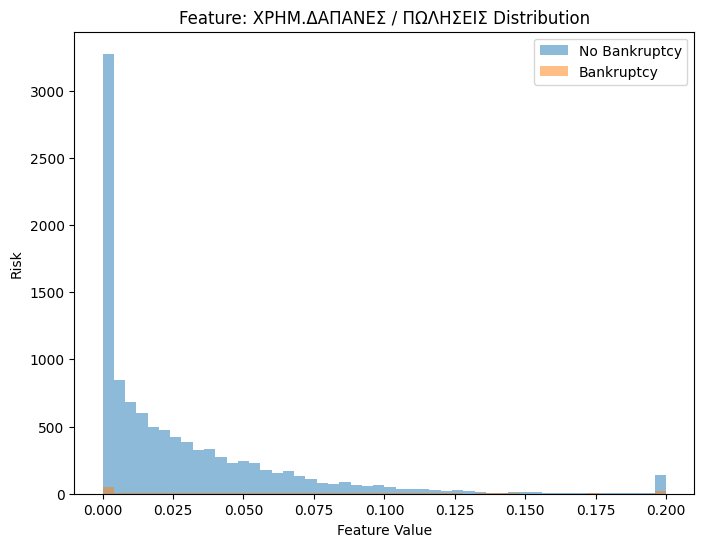

Υπάρχει ένα imbalanced σύνολο δεδομένων. Πρέπει αυτό να αντιμετωπιστεί κατάλληλα για την καλύτερη εκπαίδευση στα δεδομένα. 


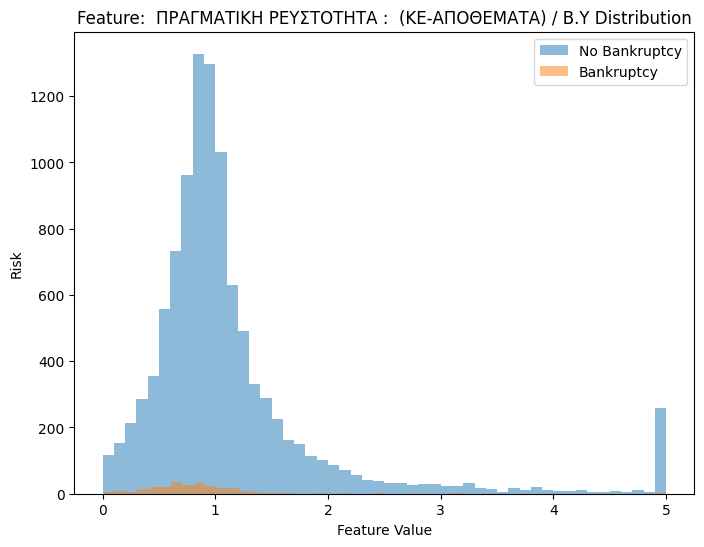

Υπάρχει ένα imbalanced σύνολο δεδομένων. Πρέπει αυτό να αντιμετωπιστεί κατάλληλα για την καλύτερη εκπαίδευση στα δεδομένα. 


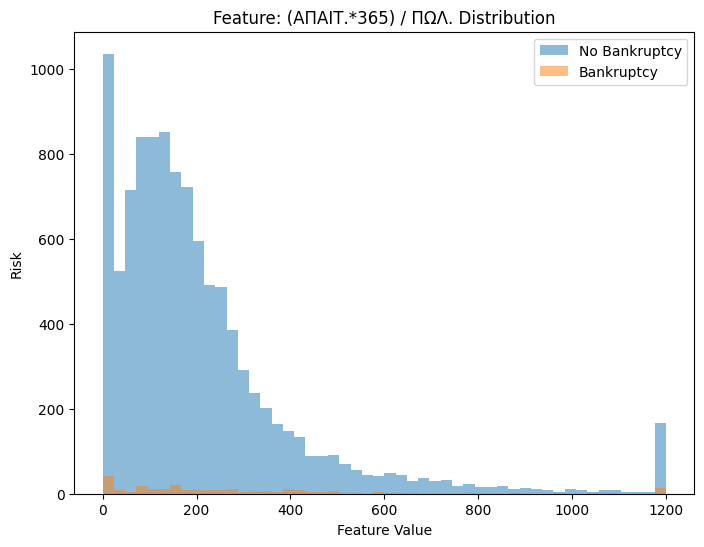

Υπάρχει ένα imbalanced σύνολο δεδομένων. Πρέπει αυτό να αντιμετωπιστεί κατάλληλα για την καλύτερη εκπαίδευση στα δεδομένα. 


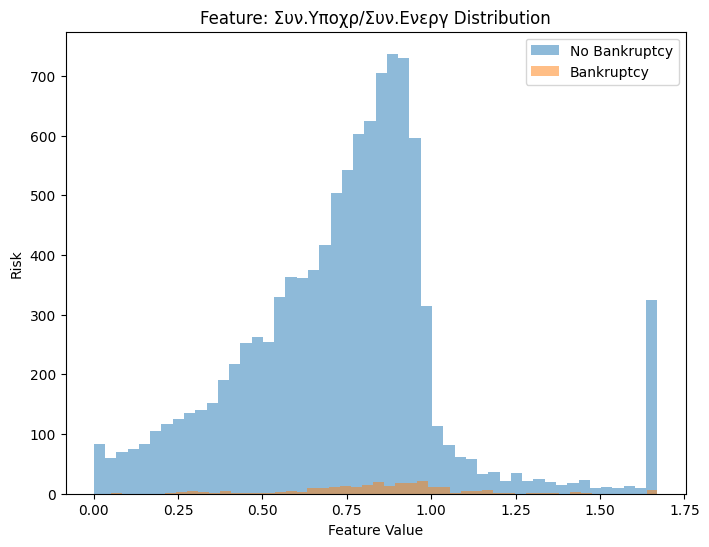

Υπάρχει ένα imbalanced σύνολο δεδομένων. Πρέπει αυτό να αντιμετωπιστεί κατάλληλα για την καλύτερη εκπαίδευση στα δεδομένα. 


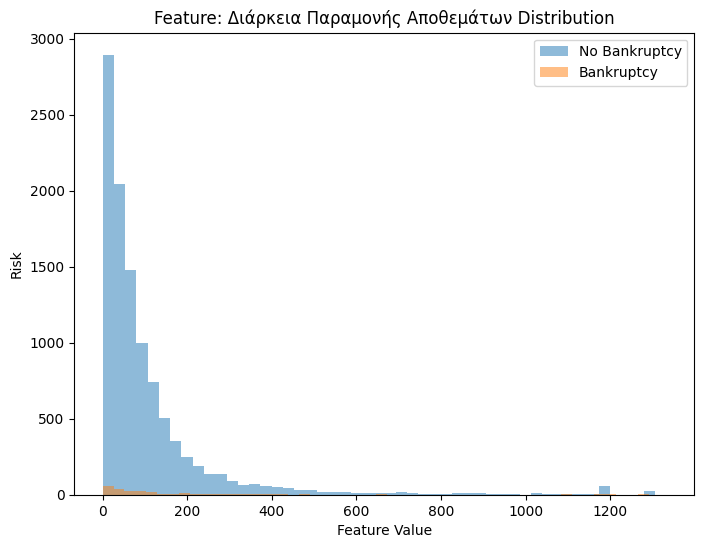

Υπάρχει ένα imbalanced σύνολο δεδομένων. Πρέπει αυτό να αντιμετωπιστεί κατάλληλα για την καλύτερη εκπαίδευση στα δεδομένα. 


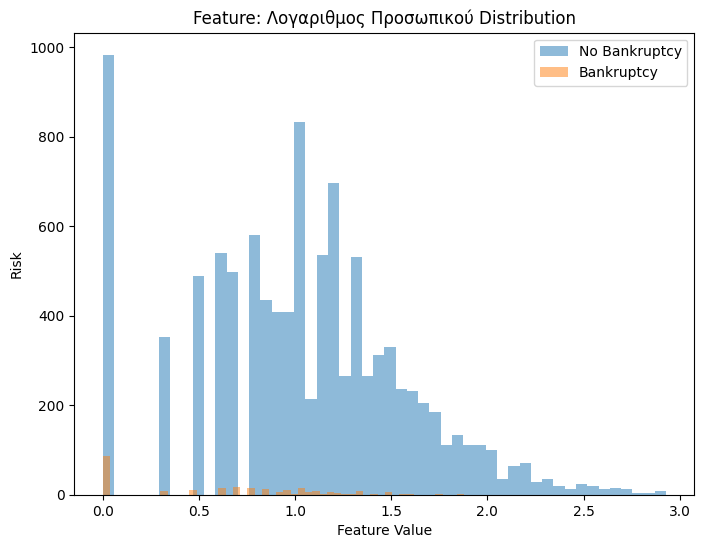

Υπάρχει ένα imbalanced σύνολο δεδομένων. Πρέπει αυτό να αντιμετωπιστεί κατάλληλα για την καλύτερη εκπαίδευση στα δεδομένα. 


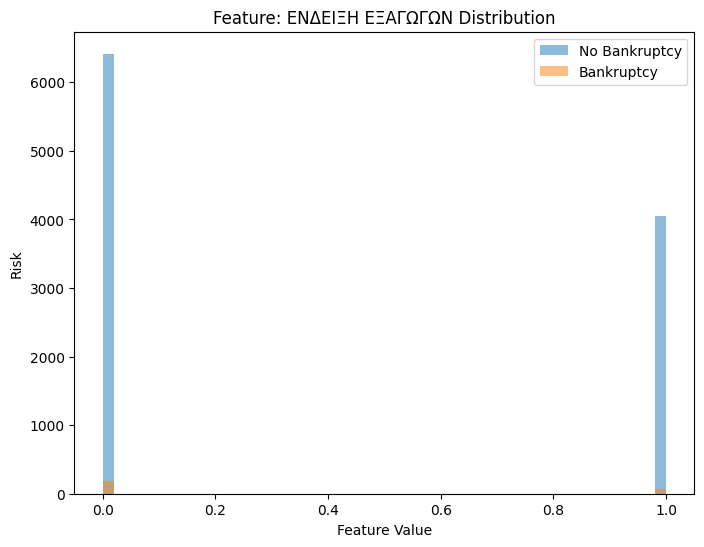

Υπάρχει ένα imbalanced σύνολο δεδομένων. Πρέπει αυτό να αντιμετωπιστεί κατάλληλα για την καλύτερη εκπαίδευση στα δεδομένα. 


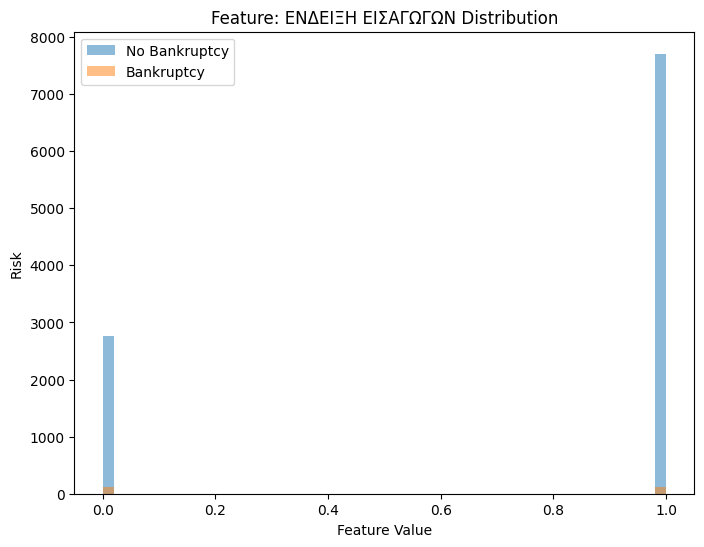

Υπάρχει ένα imbalanced σύνολο δεδομένων. Πρέπει αυτό να αντιμετωπιστεί κατάλληλα για την καλύτερη εκπαίδευση στα δεδομένα. 


In [7]:
# Iterate through each feature column
for featureIdx in range(inputData.shape[1]):
    featureName = sheetValues.columns[featureIdx]
    featureData = inputData[:, featureIdx]

    plt.figure(figsize=(8, 6))
    plt.hist(featureData[outputData == 0], bins=50, alpha=0.5, label='No Bankruptcy')
    plt.hist(featureData[outputData == 1], bins=50, alpha=0.5, label='Bankruptcy')
    plt.xlabel('Feature Value')
    plt.ylabel('Risk')
    plt.title('Feature: ' + featureName + ' Distribution')
    plt.legend()
    plt.show()
    print('Υπάρχει ένα imbalanced σύνολο δεδομένων. Πρέπει αυτό να αντιμετωπιστεί κατάλληλα για την καλύτερη εκπαίδευση στα δεδομένα. ')

In [8]:

### preprocessing
scaler = StandardScaler()
inputData_norm = scaler.fit_transform(inputData)

# Split the balanced data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(inputData_norm, outputData , test_size=0.1, random_state=100)
print(X_train.shape)
undersampler = RandomUnderSampler(sampling_strategy='majority', random_state=42)  # Undersample to have 50% of the majority class samples
X_train_res, y_train_resampled = undersampler.fit_resample(X_train, y_train)

#undersampler = RandomUnderSampler(sampling_strategy='auto')
X_train_resampled,y_train_resampled  = undersampler.fit_resample(X_train, y_train)
print(X_train_resampled.shape)

#Visualise the data
#Check the new distribution of class labels
print("After resampling:")
print("Class 0 has", len(y_train_resampled[y_train_resampled == 0]), "instances (", len(y_train_resampled[y_train_resampled == 0]) / len(y_train_resampled) * 100, "%)")
print("Class 1 has", len(y_train_resampled[y_train_resampled == 1]), "instances (", len(y_train_resampled[y_train_resampled == 1]) / len(y_train_resampled) * 100, "%)")


(9644, 10)
(452, 10)
After resampling:
Class 0 has 226 instances ( 50.0 %)
Class 1 has 226 instances ( 50.0 %)


In [9]:
X_train.shape

(9644, 10)

None


/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


Neural Network Architecture Summary:
MLPClassifier(max_iter=1000, random_state=0)


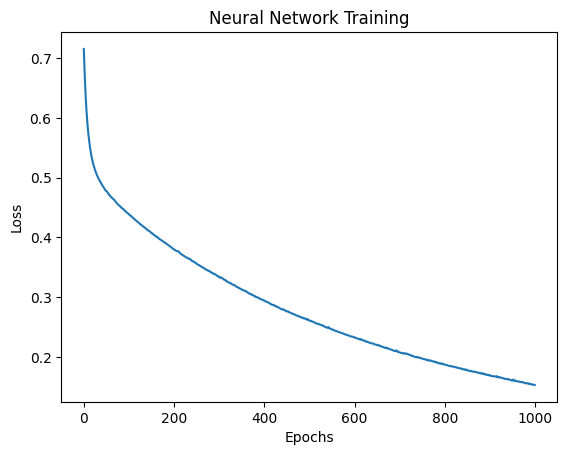

Accuracy on the Test Set:
  - Accuracy: 0.7126865671641791
  - Misclassification Rate: 0.2873134328358209


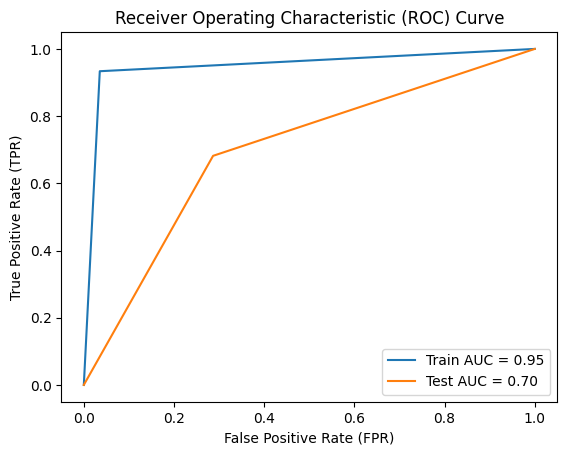

Epoch 1/100
15/15 [==============================] - 6s 4ms/step - loss: 0.6559 - accuracy: 0.6173
Epoch 2/100
15/15 [==============================] - 0s 3ms/step - loss: 0.5808 - accuracy: 0.7301
Epoch 3/100
15/15 [==============================] - 0s 3ms/step - loss: 0.5498 - accuracy: 0.7323
Epoch 4/100
15/15 [==============================] - 0s 3ms/step - loss: 0.5317 - accuracy: 0.7544
Epoch 5/100
15/15 [==============================] - 0s 3ms/step - loss: 0.5215 - accuracy: 0.7699
Epoch 6/100
15/15 [==============================] - 0s 3ms/step - loss: 0.5152 - accuracy: 0.7699
Epoch 7/100
15/15 [==============================] - 0s 3ms/step - loss: 0.5079 - accuracy: 0.7699
Epoch 8/100
15/15 [==============================] - 0s 3ms/step - loss: 0.5025 - accuracy: 0.7743
Epoch 9/100
15/15 [==============================] - 0s 3ms/step - loss: 0.4976 - accuracy: 0.7721
Epoch 10/100
15/15 [==============================] - 0s 5ms/step - loss: 0.4949 - accuracy: 0.7721
Epoch 11/

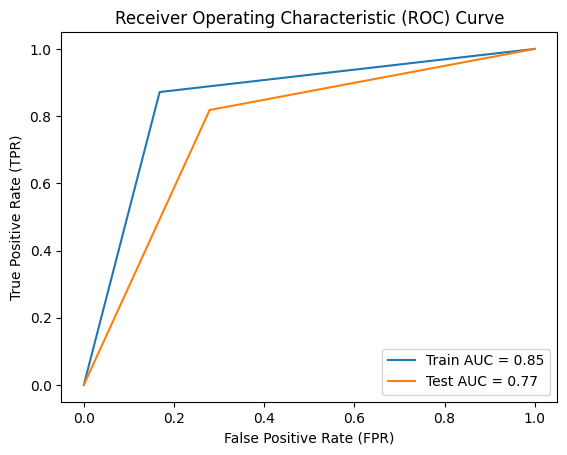

In [10]:
X_train=X_train_resampled
y_train=y_train_resampled

###############################################################################
## LOGISTIC REGRESSION
logreg = LogisticRegression()
logreg.fit(X_train, y_train)  # fit the model using the balanced training data

# Now check the performance on both train and test data
y_pred_train = logreg.predict(X_train)
y_pred_test = logreg.predict(X_test)

# Create an initial empty scores table
scores_table = None #initialize
print (scores_table)
# Call the function with appropriate arguments and append the results to the table
method_used = 'Logistic Regression'
scores_table = scores(X_train, y_train, y_pred_train, y_pred_test, method_used, scores_table)
scores_table
###############################################################################
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

## LDA
lda = LinearDiscriminantAnalysis()
lda.fit(X_train, y_train)  # fit the model using the balanced training data

# Now check the performance on both train and test data
y_pred_train_lda = lda.predict(X_train)
y_pred_test_lda = lda.predict(X_test)

# Call the scores function to calculate the evaluation metrics
method_used_lda = 'Linear Discriminant Analysis'
scores_table = scores(X_train, y_train, y_pred_train_lda, y_pred_test_lda, method_used_lda, scores_table)


###############################################################################
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

# Define the parameter grid
param_grid = {
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5],
    'max_features': ['sqrt', 'log2']
}

# Create the grid search object
grid_search = GridSearchCV(estimator=DecisionTreeClassifier(), param_grid=param_grid, cv=5)

# Fit the grid search to the training data
grid_search.fit(X_train, y_train)

# Get the best parameters
best_params = grid_search.best_params_

# Create a new DecisionTreeClassifier instance with the best parameters
clf = DecisionTreeClassifier(**best_params)

# Fit the model using the training data
clf.fit(X_train, y_train)

# Now check for both train and test data, how well the model learned the patterns
y_pred_train = clf.predict(X_train)
y_pred_test = clf.predict(X_test)

#calculate the scores
# Call the function with appropriate arguments and append the results to the table
method='DecisionTree'
scores_table = scores(X_train, y_train, y_pred_train, y_pred_test, method, scores_table)

###############################################################################
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(weights='uniform')
knn.fit(X_train, y_train) #fit the model using the training data
#now check for both train and test data, how well the model learned the patterns
y_pred_train = knn.predict(X_train)
y_pred_test = knn.predict(X_test)
#calculate the scores
# Call the function with appropriate arguments and append the results to the table
method='K nearest Neighbors'
scores_table = scores(X_train, y_train, y_pred_train, y_pred_test, method, scores_table)

###############################################################################
from sklearn.naive_bayes import GaussianNB

# Naïve Bayes
naive_bayes = GaussianNB()
naive_bayes.fit(X_train, y_train)  # fit the model using the balanced training data

# Now check the performance on both train and test data
y_pred_train_nb = naive_bayes.predict(X_train)
y_pred_test_nb = naive_bayes.predict(X_test)

# Call the scores function to calculate the evaluation metrics
method_used_nb = 'Naïve Bayes'
scores_table = scores(X_train, y_train, y_pred_train_nb, y_pred_test_nb, method_used_nb, scores_table)

###############################################################################
from sklearn.svm import SVC

# Support Vector Machine
svm = SVC()
svm.fit(X_train, y_train)  # fit the model using the balanced training data

# Now check the performance on both train and test data
y_pred_train_svm = svm.predict(X_train)
y_pred_test_svm = svm.predict(X_test)

# Call the scores function to calculate the evaluation metrics
method_used_svm = 'Support Vector Machine'
scores_table = scores(X_train, y_train, y_pred_train_svm, y_pred_test_svm, method_used_svm, scores_table)

###############################################################################
from sklearn.neural_network import MLPClassifier

# Define the Neural Network architecture
nn = MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000, random_state=0)

# Fit the model using the balanced training data
history = nn.fit(X_train, y_train)

# Now check the performance on both train and test data
y_pred_train_nn = nn.predict(X_train)
y_pred_test_nn = nn.predict(X_test)

# Call the scores function to calculate the evaluation metrics
method_used_nn = 'Neural Network MLP'
scores_table = scores(X_train, y_train, y_pred_train_nn, y_pred_test_nn, method_used_nn, scores_table)
# Evaluate the model on the validation set
loss = nn.loss_
accuracy = nn.score(X_test, y_test)

# Print the summary of the Neural Network architecture
print("Neural Network Architecture Summary:")
print(nn)

# Plot the loss and accuracy curves
plt.plot(history.loss_curve_)
plt.title('Neural Network Training')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()

# Print the accuracy statistics
print("Accuracy on the Test Set:")
print("  - Accuracy:", accuracy)
print("  - Misclassification Rate:", 1 - accuracy)

from sklearn.metrics import roc_auc_score, roc_curve
#Calculate the AUC score
auc_train = roc_auc_score(y_train, y_pred_train_nn)
auc_test = roc_auc_score(y_test, y_pred_test_nn)

# Calculate the False Positive Rate (FPR) and True Positive Rate (TPR) for the ROC curve
fpr_train, tpr_train, _ = roc_curve(y_train, y_pred_train_nn)
fpr_test, tpr_test, _ = roc_curve(y_test, y_pred_test_nn)

# Plot the ROC curve
plt.plot(fpr_train, tpr_train, label=f'Train AUC = {auc_train:.2f}')
plt.plot(fpr_test, tpr_test, label=f'Test AUC = {auc_test:.2f}')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.legend()
plt.show()
##################################################################################################
#finally, build a feed forward neural network using keras
import keras
from keras.models import Sequential
from keras.layers import Dense

# Define the model architecture
CustomModel = Sequential()
CustomModel.add(Dense(100, activation='relu', input_shape=(10,)))  # Adjust the number of units to 10
CustomModel.add(Dense(2, activation='softmax'))  # Adjust the number of units to 2

# Compile the model
CustomModel.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Convert the target variable to categorical format
y_train_categorical = keras.utils.to_categorical(y_train)

# Train the model
CustomModel.fit(X_train, y_train_categorical, epochs=100, verbose=True)

# Make predictions
y_pred_train = CustomModel.predict(X_train)
y_pred_test = CustomModel.predict(X_test)

# Convert the predicted probabilities to class labels
y_pred_train_labels = np.argmax(y_pred_train, axis=1)
y_pred_test_labels = np.argmax(y_pred_test, axis=1)


method_used_nn = 'Neural Network myCustom'
scores_table = scores(X_train, y_train, y_pred_train_labels, y_pred_test_labels, method_used_nn, scores_table)

#Calculate the AUC score
auc_train = roc_auc_score(y_train, y_pred_train_labels)
auc_test = roc_auc_score(y_test, y_pred_test_labels)

# Calculate the False Positive Rate (FPR) and True Positive Rate (TPR) for the ROC curve
fpr_train, tpr_train, _ = roc_curve(y_train, y_pred_train_labels)
fpr_test, tpr_test, _ = roc_curve(y_test, y_pred_test_labels)

# Plot the ROC curve
plt.plot(fpr_train, tpr_train, label=f'Train AUC = {auc_train:.2f}')
plt.plot(fpr_test, tpr_test, label=f'Test AUC = {auc_test:.2f}')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.legend()
plt.show()


In [11]:
scores_table


,Method,Sample,Number_of_training_samples,Number_of_bankrupt_companies,TP,TN,FP,FN,Precision,Recall,F1,Accuracy,Succ_rate_healthy_comp,Succ_rate_bankrupt_comp
0,Logistic Regression,Train,452,226,166,174,52,60,0.761468,0.734513,0.747748,0.752212,-,-
1,Logistic Regression,Test,1072,22,17,792,258,5,0.061818,0.772727,0.114478,0.754664,75.43%,77.27%
2,Linear Discriminant Analysis,Train,452,226,167,175,51,59,0.766055,0.738938,0.752252,0.756637,-,-
3,Linear Discriminant Analysis,Test,1072,22,18,799,251,4,0.066914,0.818182,0.123711,0.762127,76.10%,81.82%
4,DecisionTree,Train,452,226,196,197,29,30,0.871111,0.867257,0.869180,0.869469,-,-
5,DecisionTree,Test,1072,22,16,746,304,6,0.050000,0.727273,0.093567,0.710821,71.05%,72.73%
6,K nearest Neighbors,Train,452,226,186,182,44,40,0.808696,0.823009,0.815789,0.814159,-,-
7,K nearest Neighbors,Test,1072,22,16,770,280,6,0.054054,0.727273,0.100629,0.733209,73.33%,72.73%
8,Naïve Bayes,Train,452,226,162,176,50,64,0.764151,0.716814,0.739726,0.747788,-,-
9,Naïve Bayes,Test,1072,22,16,819,231,6,0.064777,0.727273,0.118959,0.778918,78.00%,72.73%


Παρατηρώντας τον παραπάνω πίνακα είναι ξεκάθαρο ότι τα support Vector Machines  έχουν την καλύτερη επιτυχία σε σχέση με τα υπόλοιπα μοντέλα, καθώς τόσο το success rate των υγιών και των bankrupt είναι ο μεγαλύτερος δυνατός.  Να αναφερθεί ότι η επιτυχία μεταξύ όλων των μοντέλων θα μπορούσε να αξιολογηθεί χρησιμοποιώντας AUC curves και συγκεκριμένα η ποιότητα αξιολογείται κυρίως από το μέτρο πιστότητας του precision. To συγκεκριμένο μέτρο έχει μεγάλη σημασία καθώς μπορεί να περιγράψει επιτυχώς imbalanced data στα οποία η σημαντική ομάδα που με καλύτερα θέλουμε να περιγραφεί ( δηλ. εδώ bankrupt) είναι και η μειονότητα.

In [12]:
# Filter the scores table for test samples
test_scores = scores_table[scores_table['Sample'] == 'Test']

# Sort the test scores table by accuracy in descending order
sorted_table = test_scores.sort_values(by='Accuracy', ascending=False)

# Get the row with the highest accuracy (best model)
best_model = sorted_table.iloc[0]

# Print the best model's information
print("Best Model:")
print(best_model)


Best Model:
Method                          Naïve Bayes
Sample                                 Test
Number_of_training_samples             1072
Number_of_bankrupt_companies             22
TP                                       16
TN                                      819
FP                                      231
FN                                        6
Precision                          0.064777
Recall                             0.727273
F1                                 0.118959
Accuracy                           0.778918
Succ_rate_healthy_comp               78.00%
Succ_rate_bankrupt_comp              72.73%
Name: 9, dtype: object


In [13]:
import csv

def save_scores_table(scores_table, filepath):
    i = 1
    with open(filepath, 'w', newline='') as csvfile:
        writer = csv.writer(csvfile, delimiter='|')
        header = scores_table.columns.tolist()
        writer.writerow(header)  # Write the column headers

        for _, row in scores_table.iterrows():
            writer.writerow(row.values)
            writer.writerow(['------------------------------------------------------------------------------------------------------------------------------'])
            if i % 2 == 0:
                writer.writerow(['------------------------------------------------------------------------------------------------------------------------------'])
            i += 1

# Example usage
save_scores_table(scores_table, '/content/drive/MyDrive/Colab Notebooks/deep Learning/scores_table2.csv')


using a feedforward neural network, such as the Multilayer Perceptron (MLP), which is a type of fully connected neural network. MLPs can be effective for classification tasks, including classifying firms into bankrupt and healthy categories based on financial indicators.


In [14]:
def save_scores_table2(scores_table, filepath):
    with open(filepath, 'w', newline='') as csvfile:
        writer = csv.writer(csvfile, delimiter='|')

        # Write the column headers
        header = scores_table.columns.tolist()
        writer.writerow(header)

        # Write each row with aligned columns
        for _, row in scores_table.iterrows():
            values = [f"{col:<25}" for col in row.values]  # Align values to the left with a width of 25
            writer.writerow(values)

            # Add a separator row after each data row
            separator = ['-' * 25] * len(values)
            writer.writerow(separator)

# Example usage
save_scores_table(scores_table, '/content/drive/MyDrive/Colab Notebooks/deep Learning/scores_table2.csv')


Αναλογία 1:3


In [15]:


# Split the balanced data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(inputData_norm, outputData , test_size=0.1, random_state=100)
print(X_train.shape)

#Balance the training set to have a proportion of 3 healthy businesses to 1 bankrupt:
#sampler = RandomUnderSampler(sampling_strategy={1: sum(y_train == 1 ) * 3})

X_train_with_y1 = X_train[y_train == 1]
y_train_with_y1 = y_train[y_train == 1]

X_train_balanced = []
y_train_balanced = []

# Append rows from X_train_with_y1 and corresponding y_train_with_y1 to X_train_balanced and y_train_balanced
for row, label in zip(X_train_with_y1, y_train_with_y1):
    X_train_balanced.append(row)
    y_train_balanced.append(label)
    # Append three random samples from X_train[y_train == 0] to X_train_balanced and y_train_balanced
    random_indices = np.random.choice(np.where(y_train == 0)[0], size=3, replace=False)
    for idx in random_indices:
        X_train_balanced.append(X_train[idx])
        y_train_balanced.append(y_train[idx])



# Convert X_train_balanced and y_train_balanced to NumPy arrays
X_train_balanced = np.array(X_train_balanced)
y_train_balanced = np.array(y_train_balanced)


# Shuffle X_train_balanced and y_train_balanced in the same order
shuffle_indices = np.arange(len(X_train_balanced))
np.random.shuffle(shuffle_indices)

X_train_balanced_shuffled = X_train_balanced[shuffle_indices]
y_train_balanced_shuffled = y_train_balanced[shuffle_indices]

# Print the shuffled X_train_balanced and y_train_balanced
print("Shuffled X_train_balanced:")
print(X_train_balanced_shuffled.shape)
print("\nShuffled y_train_balanced:")
print(y_train_balanced_shuffled.shape)

#Visualise the data
#Check the new distribution of class labels
print("After resampling:")
print("Class 0 has", len(y_train_balanced_shuffled[y_train_balanced_shuffled == 0]), "instances (", len(y_train_balanced_shuffled[y_train_balanced_shuffled == 0]) / len(y_train_balanced_shuffled) * 100, "%)")
print("Class 1 has", len(y_train_balanced_shuffled[y_train_balanced_shuffled == 1]), "instances (", len(y_train_balanced_shuffled[y_train_balanced_shuffled == 1]) / len(y_train_balanced_shuffled) * 100, "%)")


(9644, 10)
Shuffled X_train_balanced:
(904, 10)

Shuffled y_train_balanced:
(904,)
After resampling:
Class 0 has 678 instances ( 75.0 %)
Class 1 has 226 instances ( 25.0 %)


None


/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


Neural Network Architecture Summary:
MLPClassifier(max_iter=1000, random_state=0)


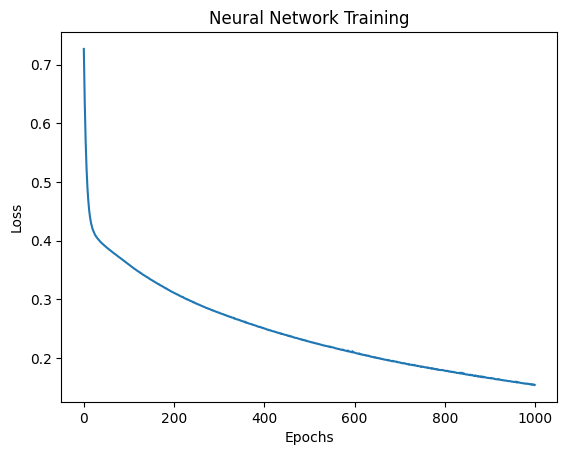

Accuracy on the Test Set:
  - Accuracy: 0.8722014925373134
  - Misclassification Rate: 0.12779850746268662


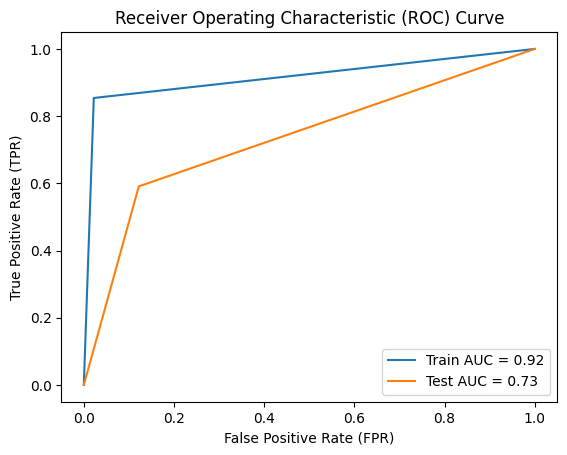

Epoch 1/100
29/29 [==============================] - 1s 3ms/step - loss: 0.5930 - accuracy: 0.7168
Epoch 2/100
29/29 [==============================] - 0s 3ms/step - loss: 0.4791 - accuracy: 0.7954
Epoch 3/100
29/29 [==============================] - 0s 3ms/step - loss: 0.4399 - accuracy: 0.8075
Epoch 4/100
29/29 [==============================] - 0s 3ms/step - loss: 0.4258 - accuracy: 0.7998
Epoch 5/100
29/29 [==============================] - 0s 3ms/step - loss: 0.4175 - accuracy: 0.8086
Epoch 6/100
29/29 [==============================] - 0s 3ms/step - loss: 0.4135 - accuracy: 0.8186
Epoch 7/100
29/29 [==============================] - 0s 3ms/step - loss: 0.4077 - accuracy: 0.8175
Epoch 8/100
29/29 [==============================] - 0s 3ms/step - loss: 0.4046 - accuracy: 0.8197
Epoch 9/100
29/29 [==============================] - 0s 3ms/step - loss: 0.4029 - accuracy: 0.8175
Epoch 10/100
29/29 [==============================] - 0s 3ms/step - loss: 0.4012 - accuracy: 0.8186
Epoch 11/

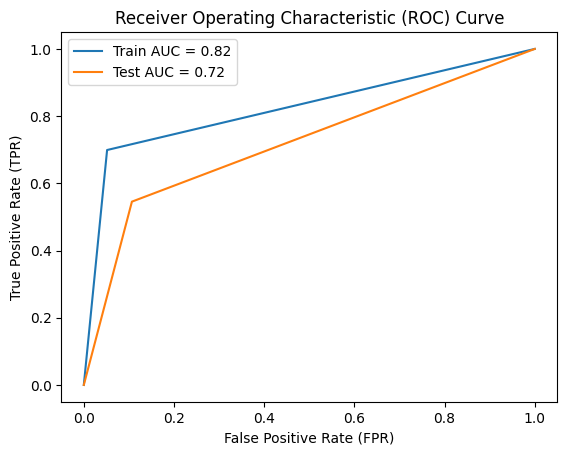

In [16]:
X_train=X_train_balanced_shuffled
y_train=y_train_balanced_shuffled
###############################################################################
## LOGISTIC REGRESSION
logreg = LogisticRegression()
logreg.fit(X_train, y_train)  # fit the model using the balanced training data

# Now check the performance on both train and test data
y_pred_train = logreg.predict(X_train)
y_pred_test = logreg.predict(X_test)

# Create an initial empty scores table
scores_table = None #initialize
print (scores_table)
# Call the function with appropriate arguments and append the results to the table
method_used = 'Logistic Regression'
scores_table = scores(X_train, y_train, y_pred_train, y_pred_test, method_used, scores_table)
scores_table
###############################################################################
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

## LDA
lda = LinearDiscriminantAnalysis()
lda.fit(X_train, y_train)  # fit the model using the balanced training data

# Now check the performance on both train and test data
y_pred_train_lda = lda.predict(X_train)
y_pred_test_lda = lda.predict(X_test)

# Call the scores function to calculate the evaluation metrics
method_used_lda = 'Linear Discriminant Analysis'
scores_table = scores(X_train, y_train, y_pred_train_lda, y_pred_test_lda, method_used_lda, scores_table)


###############################################################################
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

# Define the parameter grid
param_grid = {
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5],
    'max_features': ['sqrt', 'log2']
}

# Create the grid search object
grid_search = GridSearchCV(estimator=DecisionTreeClassifier(), param_grid=param_grid, cv=5)

# Fit the grid search to the training data
grid_search.fit(X_train, y_train)

# Get the best parameters
best_params = grid_search.best_params_

# Create a new DecisionTreeClassifier instance with the best parameters
clf = DecisionTreeClassifier(**best_params)

# Fit the model using the training data
clf.fit(X_train, y_train)

# Now check for both train and test data, how well the model learned the patterns
y_pred_train = clf.predict(X_train)
y_pred_test = clf.predict(X_test)

#calculate the scores
# Call the function with appropriate arguments and append the results to the table
method='DecisionTree'
scores_table = scores(X_train, y_train, y_pred_train, y_pred_test, method, scores_table)

###############################################################################
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(weights='uniform')
knn.fit(X_train, y_train) #fit the model using the training data
#now check for both train and test data, how well the model learned the patterns
y_pred_train = knn.predict(X_train)
y_pred_test = knn.predict(X_test)
#calculate the scores
# Call the function with appropriate arguments and append the results to the table
method='K nearest Neighbors'
scores_table = scores(X_train, y_train, y_pred_train, y_pred_test, method, scores_table)

###############################################################################
from sklearn.naive_bayes import GaussianNB

# Naïve Bayes
naive_bayes = GaussianNB()
naive_bayes.fit(X_train, y_train)  # fit the model using the balanced training data

# Now check the performance on both train and test data
y_pred_train_nb = naive_bayes.predict(X_train)
y_pred_test_nb = naive_bayes.predict(X_test)

# Call the scores function to calculate the evaluation metrics
method_used_nb = 'Naïve Bayes'
scores_table = scores(X_train, y_train, y_pred_train_nb, y_pred_test_nb, method_used_nb, scores_table)

################################################################################
from sklearn.svm import SVC

# Support Vector Machine
svm = SVC()
svm.fit(X_train, y_train)  # fit the model using the balanced training data

# Now check the performance on both train and test data
y_pred_train_svm = svm.predict(X_train)
y_pred_test_svm = svm.predict(X_test)

# Call the scores function to calculate the evaluation metrics
method_used_svm = 'Support Vector Machine'
scores_table = scores(X_train, y_train, y_pred_train_svm, y_pred_test_svm, method_used_svm, scores_table)

################################################################################
#from sklearn.neural_network import MLPClassifier

# Define the Neural Network architecture
nn = MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000, random_state=0)

# Fit the model using the balanced training data
history = nn.fit(X_train, y_train)

# Now check the performance on both train and test data
y_pred_train_nn = nn.predict(X_train)
y_pred_test_nn = nn.predict(X_test)

# Call the scores function to calculate the evaluation metrics
method_used_nn = 'Neural Network MLP'
scores_table = scores(X_train, y_train, y_pred_train_nn, y_pred_test_nn, method_used_nn, scores_table)
# Evaluate the model on the validation set
loss = nn.loss_
accuracy = nn.score(X_test, y_test)

# Print the summary of the Neural Network architecture
print("Neural Network Architecture Summary:")
print(nn)

# Plot the loss and accuracy curves
plt.plot(history.loss_curve_)
plt.title('Neural Network Training')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()

# Print the accuracy statistics
print("Accuracy on the Test Set:")
print("  - Accuracy:", accuracy)
print("  - Misclassification Rate:", 1 - accuracy)

from sklearn.metrics import roc_auc_score, roc_curve
#Calculate the AUC score
auc_train = roc_auc_score(y_train, y_pred_train_nn)
auc_test = roc_auc_score(y_test, y_pred_test_nn)

# Calculate the False Positive Rate (FPR) and True Positive Rate (TPR) for the ROC curve
fpr_train, tpr_train, _ = roc_curve(y_train, y_pred_train_nn)
fpr_test, tpr_test, _ = roc_curve(y_test, y_pred_test_nn)

# Plot the ROC curve
plt.plot(fpr_train, tpr_train, label=f'Train AUC = {auc_train:.2f}')
plt.plot(fpr_test, tpr_test, label=f'Test AUC = {auc_test:.2f}')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.legend()
plt.show()
##################################################################################################
#finally, build a feed forward neural network using keras
import keras
from keras.models import Sequential
from keras.layers import Dense

# Define the model architecture
CustomModel = Sequential()
CustomModel.add(Dense(100, activation='relu', input_shape=(10,)))  # Adjust the number of units to 10
CustomModel.add(Dense(2, activation='softmax'))  # Adjust the number of units to 2

# Compile the model
CustomModel.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Convert the target variable to categorical format
y_train_categorical = keras.utils.to_categorical(y_train)

# Train the model
CustomModel.fit(X_train, y_train_categorical, epochs=100, verbose=True)

# Make predictions
y_pred_train = CustomModel.predict(X_train)
y_pred_test = CustomModel.predict(X_test)

# Convert the predicted probabilities to class labels
y_pred_train_labels = np.argmax(y_pred_train, axis=1)
y_pred_test_labels = np.argmax(y_pred_test, axis=1)


method_used_nn = 'Neural Network myCustom'
scores_table = scores(X_train, y_train, y_pred_train_labels, y_pred_test_labels, method_used_nn, scores_table)

#Calculate the AUC score
auc_train = roc_auc_score(y_train, y_pred_train_labels)
auc_test = roc_auc_score(y_test, y_pred_test_labels)

# Calculate the False Positive Rate (FPR) and True Positive Rate (TPR) for the ROC curve
fpr_train, tpr_train, _ = roc_curve(y_train, y_pred_train_labels)
fpr_test, tpr_test, _ = roc_curve(y_test, y_pred_test_labels)

# Plot the ROC curve
plt.plot(fpr_train, tpr_train, label=f'Train AUC = {auc_train:.2f}')
plt.plot(fpr_test, tpr_test, label=f'Test AUC = {auc_test:.2f}')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.legend()
plt.show()


################################################################################

Η rOC Curve δείχνει πως όποιο μοντέλο είναι πιο μακρυά από τη διαγώνιο είναι και καλύτερα εκπαιδευμένο. Στο  συγκεκριμένο παράδειγμα συγκρίνουμε validation kai training και όπως ήταν προφανές καλύτερο φαίνεται το training set στην εκπαίδευση.

In [17]:
# Save scores Table
save_scores_table(scores_table, '/content/drive/MyDrive/Colab Notebooks/deep Learning/scores_table_1b.csv')


Με τη χρήση της αναλογία 1:3 τα αποτελέσματα είναι πολύ χειρότερα. Φαινεται πως ακόμα πιο δύσκολα διακρίνεται κάποιο pattern των δεδομένων, δηλαδή και η εκπαίδευσή τους ήταν χειρότερη και πιο δύσκολη. Στην πραγματικότητα επειδή τα δεδομένα είναι imbalanced δεν είναι δυνατή έτσι απλά να γίνει σωστή προεπεξεργασία των δεδομένων για να διασφαλιστεί υψηλό precisiion. Ο αλγόριθμος εδώ φαίνεται να αποτυχαίνε μπορστά στις προδιαγραφές που τέθηκαν στο πρώτο ερώτημα.


In [18]:
best_params

{'max_depth': 5,
 'max_features': 'sqrt',
 'min_samples_leaf': 1,
 'min_samples_split': 5}